# Amazon Alexa Review - Sentiment Analysis

Analyzing the Amazon Alexa dataset and buliding classification models to predict if the sentiment of a given input sentence is positive or negative.

## Importing required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.stem.porter import PorterStemmer
nltk.download("stopwords")
from nltk.corpus import stopwords
stopwords = set(stopwords.words('english'))

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.tree import DecisionTreeClassifier

from wordcloud import WordCloud
from xgboost import XGBClassifier
import pickle
import re

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ashit/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Exploratory Data Analysis

In [2]:
# Load the data
data = pd.read_csv("amazon_alexa.tsv", delimiter = '\t', quoting = 3)
print(f"Dataset Shape: {data.shape}")

Dataset Shape: (3150, 5)


In [3]:
data.head()

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"""Sometimes while playing a game, you can answe...",1
3,5,31-Jul-18,Charcoal Fabric,"""I have had a lot of fun with this thing. My 4...",1
4,5,31-Jul-18,Charcoal Fabric,Music,1


In [4]:
# Columnn Names
print(f"Features Names: {data.columns.values}")

Features Names: ['rating' 'date' 'variation' 'verified_reviews' 'feedback']


In [5]:
# Checking for null values
data.isnull().sum()

rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64

In [6]:
# Getting the record where "verified_reviews" is null
data[data['verified_reviews'].isna()==True]

,rating,date,variation,verified_reviews,feedback
473,2,29-Jun-18,White,NaN,0


In [7]:
# we will drop null value
data.dropna(inplace=True)

In [8]:
print(f"dataset shape after dropping null value: {data.shape}")

dataset shape after dropping null value: (3149, 5)


In [9]:
# Creating a new column "length" that will contain the length of the string in "verified_reviews" column
data['length'] = data['verified_reviews'].apply(len)

In [10]:
data.head()

,rating,date,variation,verified_reviews,feedback,length
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1,13
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1,9
2,4,31-Jul-18,Walnut Finish,"""Sometimes while playing a game, you can answe...",1,197
3,5,31-Jul-18,Charcoal Fabric,"""I have had a lot of fun with this thing. My 4...",1,174
4,5,31-Jul-18,Charcoal Fabric,Music,1,5


#### Datatypes of the features

In [11]:
data.dtypes

rating               int64
date                object
variation           object
verified_reviews    object
feedback             int64
length               int64
dtype: object

### Analyzing 'rating' column

This column refers to rating of the variation given by the user

In [12]:
# distinct value of ratings and its count
print(f"Rating Value Count: \n{data['rating'].value_counts()}")

Rating Value Count: 
rating
5    2286
4     455
1     161
3     152
2      95
Name: count, dtype: int64


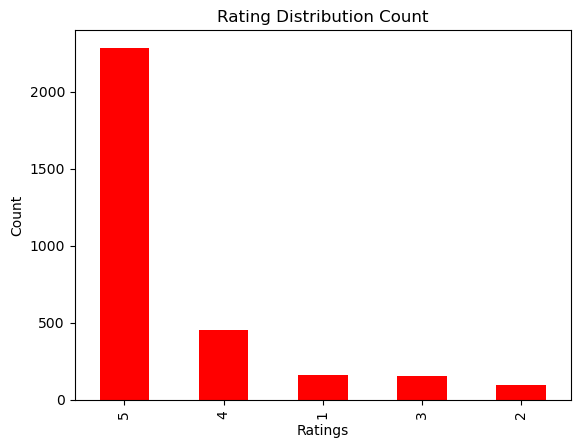

In [13]:
# bar plot to visulaizing the total counts of each rating
data['rating'].value_counts().plot.bar(color = 'r')
plt.title('Rating Distribution Count')
plt.xlabel('Ratings')
plt.ylabel("Count")
plt.show()

In [14]:
# finding the percentage disttributing of each rating - we'll divide the number of records for each rating by total no. of record
print(f"Rating value count - percentage distribution: \n{round(data['rating'].value_counts()/data.shape[0]*100,2)}")

Rating value count - percentage distribution: 
rating
5    72.59
4    14.45
1     5.11
3     4.83
2     3.02
Name: count, dtype: float64


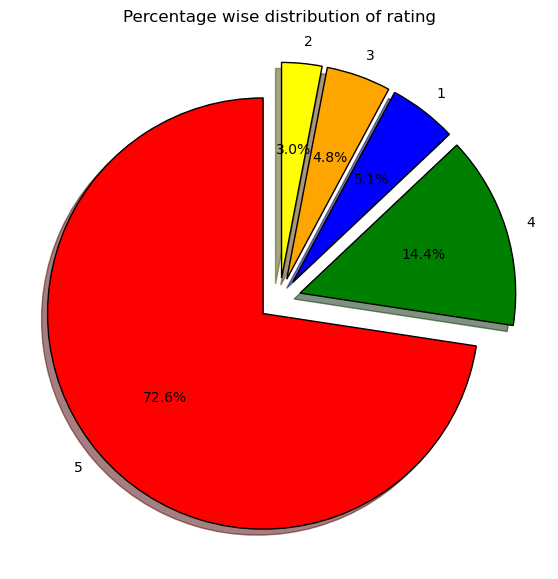

In [15]:
fig = plt.figure(figsize = (7,7))
colors = ('red', 'green', 'blue', 'orange', 'yellow')
wp = {'linewidth': 1, 'edgecolor': 'black'}
tags = data['rating'].value_counts()/data.shape[0]
explode = (0.1, 0.1, 0.1, 0.1, 0.1)
plt.pie(tags, labels = tags.index, colors = colors, explode = explode, wedgeprops = wp, autopct = '%1.1f%%', startangle = 90, shadow = True)
plt.title('Percentage wise distribution of rating')
plt.show()
from io import BytesIO
graph = BytesIO()
fig.savefig(graph, format= "png")

### Analyzing 'Feedback' Column

In [16]:
# Distinct values of 'feedback' and its count
print(f'Feedback value count: \n{data['feedback'].value_counts()}' )

Feedback value count: 
feedback
1    2893
0     256
Name: count, dtype: int64


1 refers positive review

0 refers negative reviews

In [17]:
#Extracting the 'verified_reviews' value for one record with feedback = 0
record_0 = data[data['feedback'] == 0].iloc[1]['verified_reviews']
print(record_0)

Sound is terrible if u want good music too get a bose


In [18]:
#Extracting the 'verified_reviews' value for one record with feedback = 1

record_1 = data[data['feedback'] == 1].iloc[1]['verified_reviews']
print(record_1)

Loved it!


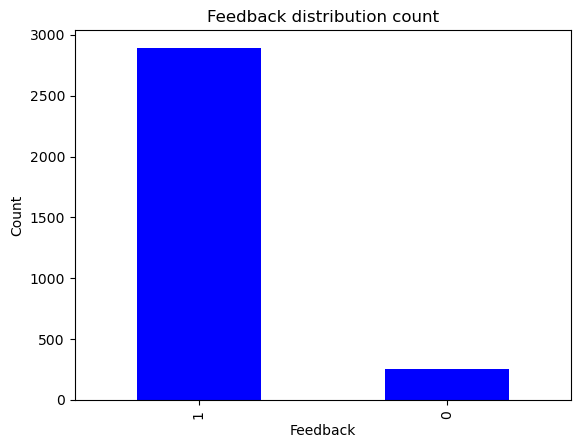

In [19]:
# Bar graph to visualize the total counts of each feedback

data['feedback'].value_counts().plot.bar(color = 'blue')
plt.title("Feedback distribution count")
plt.xlabel('Feedback')
plt.ylabel("Count")
plt.show()

In [20]:
#finding the precentage distribution of each feedback - we'll divide the no. of record for each feedback by total no. of record

print(f'Feedback Value Count - percentage destribution ;\n {round(data['feedback'].value_counts()/data.shape[0]*100, 2)}')

Feedback Value Count - percentage destribution ;
 feedback
1    91.87
0     8.13
Name: count, dtype: float64


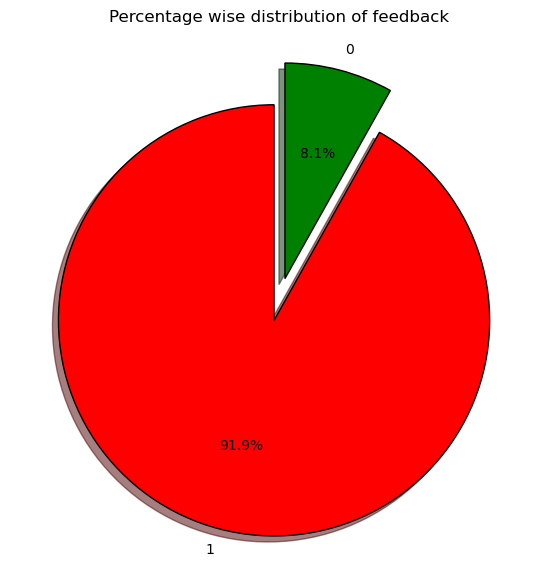

In [21]:
fig = plt.figure(figsize = (7,7))
color = ('red', 'green')
wp = {'linewidth': 1, "edgecolor": "black"}
tags = data['feedback'].value_counts()/data.shape[0]
explode = (0.1, 0.1)
plt.pie(tags, labels= tags.index, colors = color, explode = explode, wedgeprops = wp, autopct = '%1.1f%%', startangle = 90, shadow = True)
plt.title('Percentage wise distribution of feedback')
plt.show()

Lets see the 'rating' values for different values of feedback

In [22]:
# feedback = 0 negative feedback
data[data['feedback']== 0]['rating'].value_counts()

rating
1    161
2     95
Name: count, dtype: int64

In [23]:
#Feedback = 1 positive feedback
data[data['feedback'] == 1]['rating'].value_counts()

rating
5    2286
4     455
3     152
Name: count, dtype: int64

##### If rating of review is 1 and 2 then the feedback is 0 and if the rating o review is 5,4 or 3 then the feedback is 1...

### Analyzing 'Variation' column

This column refers to the variation or type of Amazon Alexa product. Example - Black Dot, Charcoal Fabric etc.

In [24]:
# Distinct  values of 'variation' and its count

print(f'Variation value count: \n{data['variation'].value_counts()}')

Variation value count: 
variation
Black  Dot                      516
Charcoal Fabric                 430
Configuration: Fire TV Stick    350
Black  Plus                     270
Black  Show                     265
Black                           261
Black  Spot                     241
White  Dot                      184
Heather Gray Fabric             157
White  Spot                     109
Sandstone Fabric                 90
White                            90
White  Show                      85
White  Plus                      78
Oak Finish                       14
Walnut Finish                     9
Name: count, dtype: int64


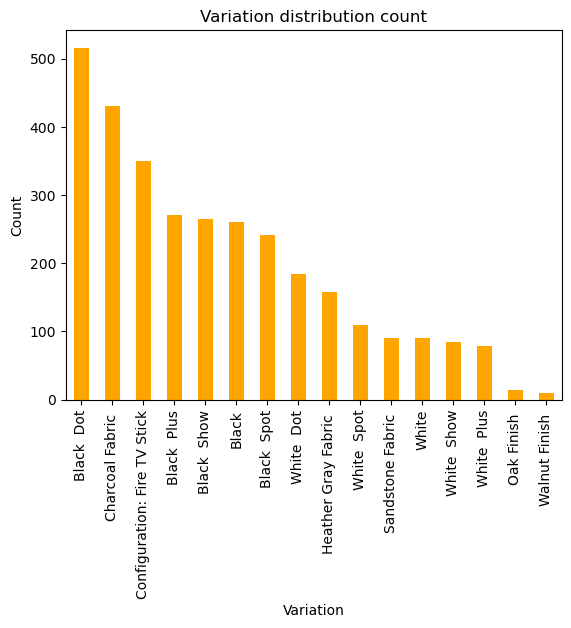

In [25]:
# bar graph to visualize the total counts of each variation

data['variation'].value_counts().plot.bar(color= "orange")
plt.title('Variation distribution count')
plt.xlabel("Variation")
plt.ylabel("Count")
plt.show()

In [26]:
# Finding percentage distribution of each variation - we'll divide the no. of records for each variation by total no. of records

print(f'Variation Value count- percentage distribution:\n{round(data['variation'].value_counts()/data.shape[0]*100,2)}')

Variation Value count- percentage distribution:
variation
Black  Dot                      16.39
Charcoal Fabric                 13.66
Configuration: Fire TV Stick    11.11
Black  Plus                      8.57
Black  Show                      8.42
Black                            8.29
Black  Spot                      7.65
White  Dot                       5.84
Heather Gray Fabric              4.99
White  Spot                      3.46
Sandstone Fabric                 2.86
White                            2.86
White  Show                      2.70
White  Plus                      2.48
Oak Finish                       0.44
Walnut Finish                    0.29
Name: count, dtype: float64


Mean Rating accroding to variation

In [27]:
data.groupby('variation')['rating'].mean()

variation
Black                           4.233716
Black  Dot                      4.453488
Black  Plus                     4.370370
Black  Show                     4.490566
Black  Spot                     4.311203
Charcoal Fabric                 4.730233
Configuration: Fire TV Stick    4.591429
Heather Gray Fabric             4.694268
Oak Finish                      4.857143
Sandstone Fabric                4.355556
Walnut Finish                   4.888889
White                           4.166667
White  Dot                      4.423913
White  Plus                     4.358974
White  Show                     4.282353
White  Spot                     4.311927
Name: rating, dtype: float64

Let's analyze the above ratings

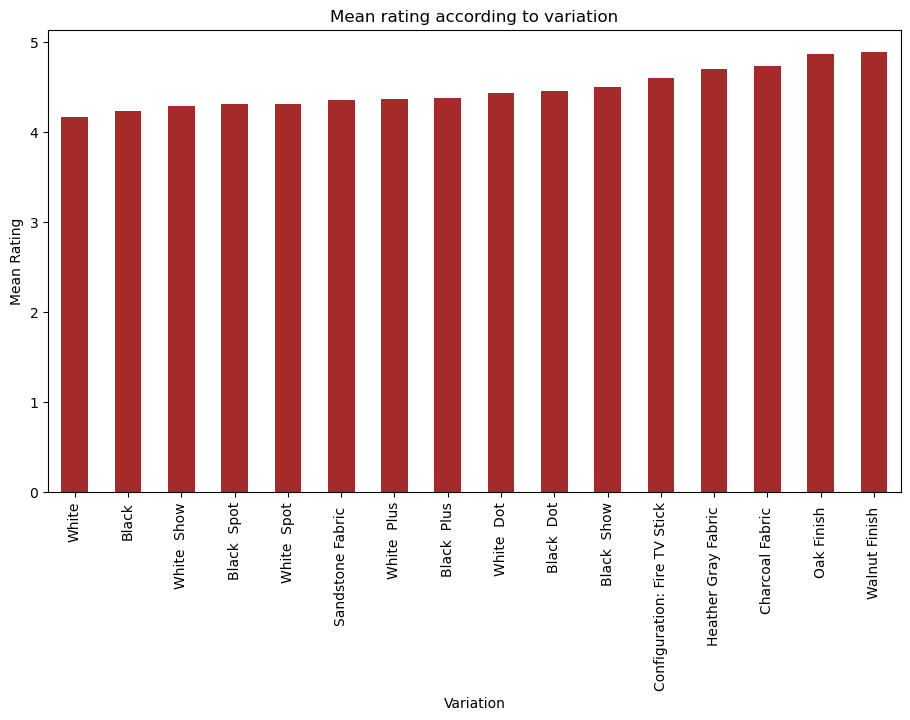

In [28]:
data.groupby('variation')['rating'].mean().sort_values().plot.bar(color = 'brown', figsize = (11,6))
plt.title('Mean rating according to variation')
plt.xlabel("Variation")
plt.ylabel("Mean Rating")
plt.show()

### Analyzing 'verified_reviews' column 

This column contain the textual review given by the user for the variation of the product

In [29]:
print(data[data['length'] == 2853]['verified_reviews'])

2016    "Incredible piece of technology.I have this ri...
Name: verified_reviews, dtype: object


In [30]:
data['length'].describe()

count    3149.000000
mean      132.714513
std       182.541531
min         1.000000
25%        30.000000
50%        74.000000
75%       166.000000
max      2853.000000
Name: length, dtype: float64

Length Analysis of full dataset

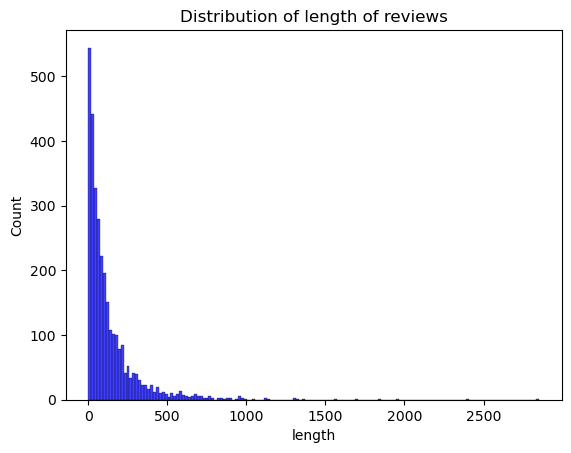

In [31]:
sns.histplot(data['length'], color = 'blue')
plt.title('Distribution of length of reviews')
plt.show()

Length analysis when feedback is 0 (negative)

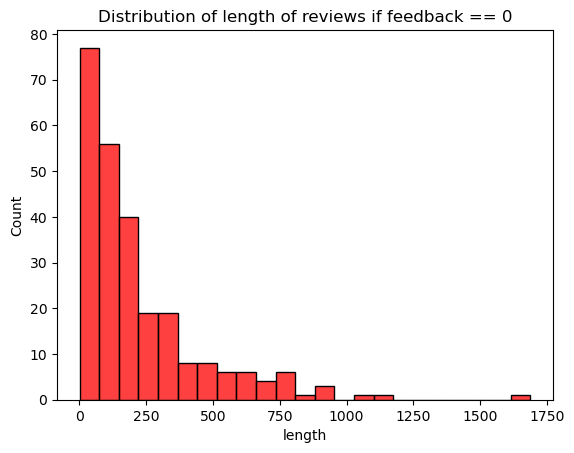

In [32]:
sns.histplot(data[data['feedback']==0]['length'], color = 'red')
plt.title('Distribution of length of reviews if feedback == 0')
plt.show()

Length analysis when feedback is 1 (positive)

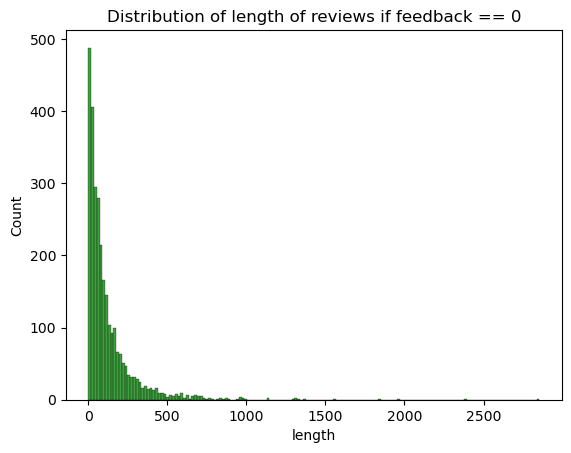

In [33]:
sns.histplot(data[data['feedback']==1]['length'], color = 'green')
plt.title('Distribution of length of reviews if feedback == 0')
plt.show()

Lengthwise mean rating

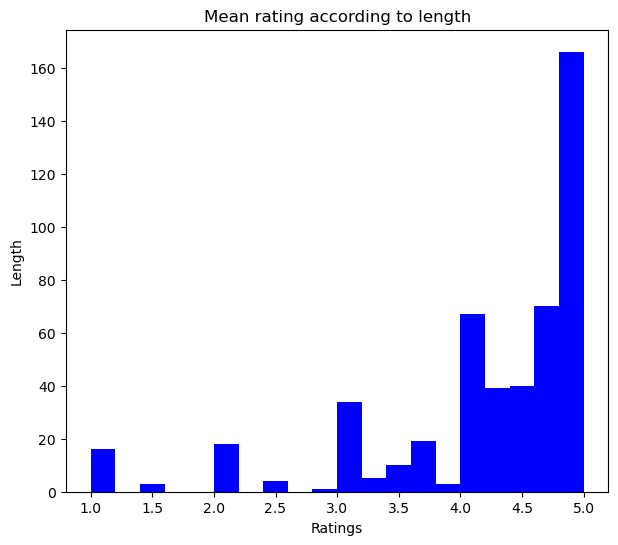

In [34]:
data.groupby('length')['rating'].mean().plot.hist(color = 'blue', figsize = (7,6) , bins = 20)
plt.title('Mean rating according to length')
plt.xlabel("Ratings")
plt.ylabel("Length")
plt.show()

In [35]:
data.head()

,rating,date,variation,verified_reviews,feedback,length
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1,13
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1,9
2,4,31-Jul-18,Walnut Finish,"""Sometimes while playing a game, you can answe...",1,197
3,5,31-Jul-18,Charcoal Fabric,"""I have had a lot of fun with this thing. My 4...",1,174
4,5,31-Jul-18,Charcoal Fabric,Music,1,5


### Convert Textual Data into numerical data so that machine can understand

In [36]:
cv = CountVectorizer(stop_words='english')
words = cv.fit_transform(data.verified_reviews)


In [37]:
# Combine all Reviews
reviews = " ".join([review for review in data['verified_reviews']])
reviews

'Love my Echo! Loved it! "Sometimes while playing a game, you can answer a question correctly but Alexa says you got it wrong and answers the same as you.  I like being able to turn lights on and off while away from home." "I have had a lot of fun with this thing. My 4 yr old learns about dinosaurs, i control the lights and play games like categories. Has nice sound when playing music as well." Music "I received the echo as a gift. I needed another Bluetooth or something to play music easily accessible, and found this smart speaker. Can’t wait to see what else it can do." "Without having a cellphone, I cannot use many of her features. I have an iPad but do not see that of any use.  It IS a great alarm.  If u r almost deaf, you can hear her alarm in the bedroom from out in the living room, so that is reason enough to keep her.It is fun to ask random questions to hear her response.  She does not seem to be very smartbon politics yet." I think this is the 5th one I\'ve purchased. I\'m wor

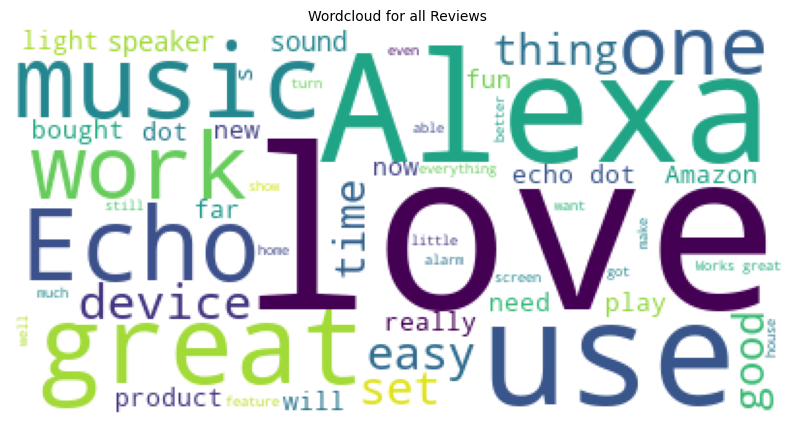

In [38]:
# Initialize wordcloud object
wc = WordCloud(max_words= 50, background_color='white')

# Generate and plot wordcloud
plt.figure(figsize = (10,10))
plt.imshow(wc.generate(reviews))
plt.title('Wordcloud for all Reviews', fontsize = 10)
plt.axis('off')
plt.show()

Lets find the unique words in each feedback category

In [39]:
# Combine all reviews for each feedback category and splitting them into individual words
neg_reviews = " ".join([review for review in data[data['feedback'] == 0]['verified_reviews']])
neg_reviews = neg_reviews.lower().split()

pos_reviews = " ".join([review for review in data[data['feedback'] == 1]['verified_reviews']])
pos_reviews = pos_reviews.lower().split()

In [40]:
# Finding words from reviews which are present in that feedback category only

unique_negative = [x for x in neg_reviews if x not in pos_reviews]
unique_negative = " ".join(unique_negative)

unique_positive = [x for x in pos_reviews if x not in neg_reviews]
unique_positive = ' '.join(unique_positive)

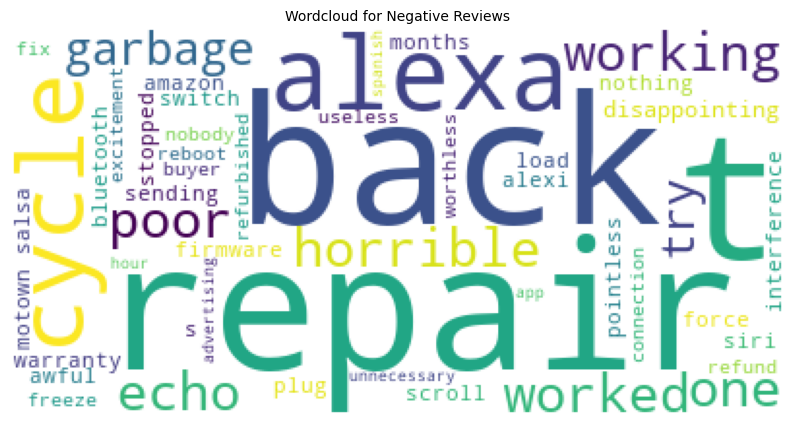

In [41]:
wc = WordCloud(background_color='white', max_words= 50)

# Generate and plot wordcloud
plt.figure(figsize = (10,10))
plt.imshow(wc.generate(unique_negative))
plt.title('Wordcloud for Negative Reviews', fontsize = 10)
plt.axis('off')
plt.show()

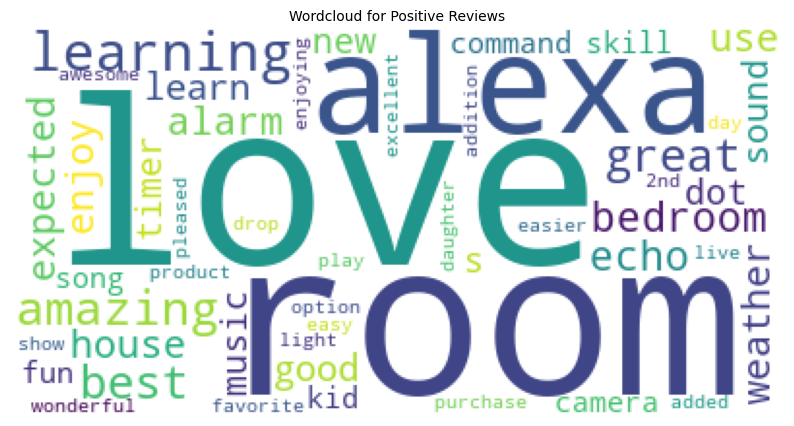

In [42]:
wc = WordCloud(background_color='white', max_words= 50)

# Generate and plot wordcloud
plt.figure(figsize = (10,10))
plt.imshow(wc.generate(unique_positive))
plt.title('Wordcloud for Positive Reviews', fontsize = 10)
plt.axis('off')
plt.show()

# Preprocessing and Modelling

To build the corpus from the 'verified_reviews' we perform the following - 
1. Replace any non alphabet characters with a space
2. Convert to lower case and split into words
3. Iterate over the individual words and if it is not a stopword then add the stemmed form of the word to the corpus

In [43]:
corpus = []
stemmer = PorterStemmer()
for i in range(0, data.shape[0]):
    review = str(data.iloc[i]['verified_reviews']) # convert to string to avoid dtype issues
    review = re.sub('[^a-zA-Z]', ' ', review)       # ✅ removes digits, punctuation, emojis
    review = review.lower().split()
    review = [stemmer.stem(word) for word in review if word not in stopwords]
    review = ' '.join(review)
    corpus.append(review)

# print(corpus[:10])

## Count Vectorization

It is used to convert text data into numerical data so that machine can understand

In [44]:
cv = CountVectorizer(max_features=2500)

#Storing independent and dependent variable x and y
x = cv.fit_transform(corpus).toarray() # numerical representation of reviews in the form of array 
y = data['feedback'].values # feedback

In [45]:
#saving the count vectorizer
pickle.dump(cv, open('countVectorizer.pkl', 'wb'))

Checking the shape of x and y

In [46]:
print(f'x shape: {x.shape}')
print(f'y shape: {y.shape}')

x shape: (3149, 2500)
y shape: (3149,)


#####  Splitting data into train and test set with 30% data with testing

In [47]:
x_train, x_test, y_train, y_test = train_test_split(x,y , test_size= 0.3, random_state=15)

print(f'x Train: {x_train.shape}')
print(f'y Train: {y_train.shape}')
print(f'x Test: {x_test.shape}')
print(f'y Test: {y_test.shape}')

x Train: (2204, 2500)
y Train: (2204,)
x Test: (945, 2500)
y Test: (945,)


In [48]:
print(f'x train max value: {x_train.max()}')
print(f'x test max value: {x_test.max()}')

x train max value: 12
x test max value: 10


We'll scale x_train and x_test so that the value are between 0 and 1

In [49]:
scaler = MinMaxScaler()

x_train_scale = scaler.fit_transform(x_train)
x_test_scale = scaler.fit_transform(x_test)

In [50]:
# saving scaler model
pickle.dump(scaler, open("scaler.pkl", 'wb'))

## Random forest Classification

In [51]:
rf = RandomForestClassifier()
rf.fit(x_train_scale, y_train)

RandomForestClassifier()

In [52]:
# Accuracy of the model on training and testing data

print(f"Training Accuracy: {rf.score(x_train_scale, y_train)*100}")
print(f"Testing Accuracy: {rf.score(x_test_scale, y_test)*100}")

Training Accuracy: 99.41016333938293
Testing Accuracy: 94.07407407407408


In [53]:
# Prediction on test set

y_pred = rf.predict(x_test_scale)

In [54]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

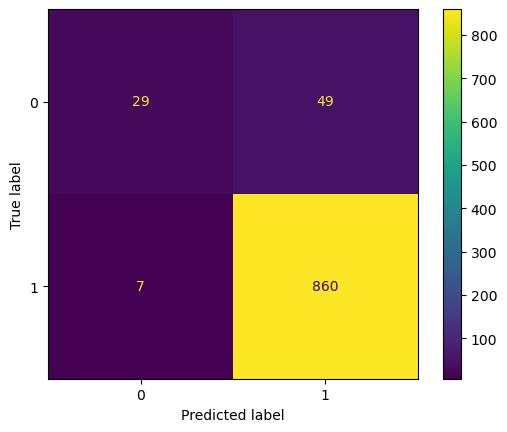

In [55]:
cm_display = ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= rf.classes_)
cm_display.plot()
plt.show()

### K-Fold cross-validation

In [56]:
accuracies = cross_val_score(estimator = rf, X = x_train_scale, y = y_train, cv = 10)

print(f'Accuracies: {accuracies.mean()}')
print(f'Standard Vairance: {accuracies.std()}')

Accuracies: 0.9333072809543397
Standard Vairance: 0.008596188711760232


Applying grid search to get the optimal parameters on random forest

In [57]:
params = {
    "bootstrap": [True],
    'max_depth': [80, 100],
    'min_samples_split': [8, 12],
    'n_estimators': [100, 300]
}

In [58]:
cv_object = StratifiedKFold(n_splits = 2)

grid_search = GridSearchCV(estimator= rf, param_grid= params , cv = cv_object, verbose= 0 , return_train_score= True)
grid_search.fit(x_train_scale, y_train.ravel())

GridSearchCV(cv=StratifiedKFold(n_splits=2, random_state=None, shuffle=False),
             estimator=RandomForestClassifier(),
             param_grid={'bootstrap': [True], 'max_depth': [80, 100],
                         'min_samples_split': [8, 12],
                         'n_estimators': [100, 300]},
             return_train_score=True)

In [59]:
# Getting the best parameters from the grid search

print(f'Best Parameter Combination: {grid_search.best_params_}')

Best Parameter Combination: {'bootstrap': True, 'max_depth': 100, 'min_samples_split': 12, 'n_estimators': 100}


In [60]:
print(f'Cross Validation mean accuracy on train set: {grid_search.cv_results_['mean_train_score'].mean()*100}')
print(f'Cross Validation mean accuracy on test set: {grid_search.cv_results_['mean_test_score'].mean()*100}')
print(f'Accuracy score for test set: {accuracy_score(y_test, y_pred)}')

Cross Validation mean accuracy on train set: 96.8296279491833
Cross Validation mean accuracy on test set: 92.15630671506352
Accuracy score for test set: 0.9407407407407408


## XgBoost

In [61]:
xgb = XGBClassifier()
xgb.fit(x_train_scale, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [62]:
#checking traing and testing score

xgb.score(x_train_scale, y_train)*100, xgb.score(x_test_scale, y_test)*100

(97.1869328493648, 93.33333333333333)

In [63]:
y_pred = xgb.predict(x_test_scale)

In [64]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[ 27,  51],
       [ 12, 855]])

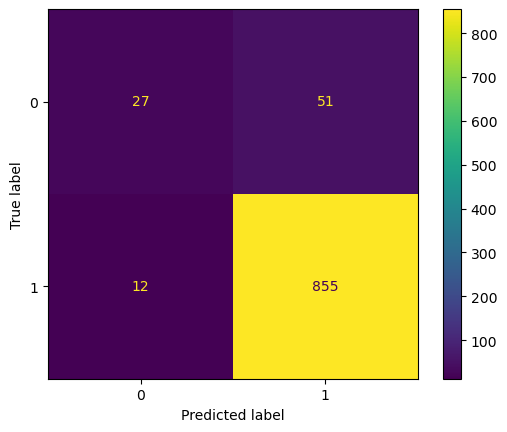

In [65]:
cm_display = ConfusionMatrixDisplay(confusion_matrix = cm,display_labels = xgb.classes_)
cm_display.plot()
plt.show()

In [66]:
# saving the XGBoost Classifier

pickle.dump(xgb, open('xgb_classifier.pkl', 'wb'))

## Decision Tree Classifier

In [67]:
dt = DecisionTreeClassifier()
dt.fit(x_train_scale, y_train)

DecisionTreeClassifier()

In [68]:
# checking score 

dt.score(x_train_scale, y_train)*100, dt.score(x_test_scale, y_test)*100

(99.41016333938293, 91.42857142857143)

In [69]:
y_pred = dt.predict(x_test_scale)

In [70]:
# confusion Matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[ 42,  36],
       [ 45, 822]])

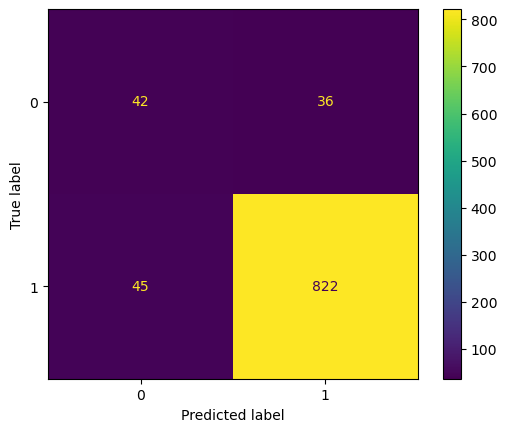

In [71]:
cm_display = ConfusionMatrixDisplay(confusion_matrix = cm , display_labels = dt.classes_ )
cm_display.plot()
plt.show()